# 1 · Datos, auditoría de limpieza y corte temporal (BTYD)

**Problema de negocio:** en el comercio minorista no contractual los clientes **no avisan cuando abandonan**: simplemente dejan de comprar. ¿Cómo distinguir a un cliente activo que compra cada pocos meses de un cliente frecuente que ya se fue en silencio?

En este notebook:
1. Auditamos y limpiamos las **1.067.371 líneas** de **UCI Online Retail II** (2009–2011).
2. Miramos la **estacionalidad** de la tienda (clave para entender la comparación con LightGBM en el notebook 2).
3. Consolidamos las transacciones por **día de compra** y construimos el corte temporal estricto (**555 días de calibración → 183 días de prueba**).
4. Revisamos las distribuciones de $x$, inactividad y ticket, y el **supuesto de independencia de Gamma-Gamma** (que solo se cumple de forma aproximada).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))

from clv import config, datos, evaluacion, predecir, segmentacion
from clv.graficos import estilo, num, AZUL, NARANJA, VERDE, AMARILLO, GRIS
estilo()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 1.1 · Auditoría de limpieza contable

In [2]:
crudo = datos.cargar_transacciones_crudas()
limpio, auditoria = datos.limpiar_transacciones(crudo)
diario = datos.agregar_compras_diarias(limpio)
display(auditoria)
print(f"Líneas limpias: {len(limpio):,} · días de compra (cliente, día): {len(diario):,} · clientes: {diario['customer_id'].nunique():,}")

,etapa,filas,importe_gbp,pct_filas
0,0. Filas crudas totales,1067371,"19,287,250.568",100.000
1,1. Excluidas: sin Customer ID (invitado),243007,"2,638,958.180",22.767
2,2. Excluidas: facturas de cancelación (C*),18744,"-1,095,136.790",1.756
3,"3. Excluidas: códigos contables/envío (POST, M...",2925,"308,964.448",0.274
4,4. Excluidas: cantidad <= 0 o precio <= 0,61,0.000,0.006
5,5. Excluidas: líneas duplicadas exactas,26055,"365,882.010",2.441
6,6. Líneas limpias retenidas,776579,"17,068,582.720",72.756


Líneas limpias: 776,579 · días de compra (cliente, día): 32,878 · clientes: 5,852


**Por qué importa cada filtro:**
- **Sin `Customer ID` (22,8 % de las filas):** ventas de invitado que no pueden asociarse a una trayectoria individual.
- **Facturas `C*` (1,8 %):** anulaciones contables.
- **Códigos no producto (`POST`, `M`, `BANK CHARGES`, `DOT`...):** envíos y ajustes que distorsionarían el ticket.
- **Agregación diaria:** dos facturas del mismo cliente el mismo día cuentan como **1 evento de compra** en los modelos *Buy Till You Die*.

In [3]:
facturas_dia = limpio.groupby(["customer_id", "fecha_dia"])["invoice"].nunique()
print(f"Días con más de una factura del mismo cliente: {(facturas_dia > 1).sum():,} de {len(facturas_dia):,} ({(facturas_dia > 1).mean() * 100:.1f} %)")
print("Sin consolidar, esos días se contarían como recompras con t_x ≈ 0.")

Días con más de una factura del mismo cliente: 2,900 de 32,878 (8.8 %)
Sin consolidar, esos días se contarían como recompras con t_x ≈ 0.


## 1.2 · Estacionalidad: el cuarto trimestre pesa mucho más

In [4]:
mensual = (
    diario.assign(mes=diario["fecha_dia"].dt.to_period("M"))
    .groupby("mes").agg(ingreso_gbp=("importe_dia", "sum"), clientes_activos=("customer_id", "nunique"))
)
mensual = mensual.iloc[:-1]  # diciembre 2011 solo tiene 9 días
fig, ax = plt.subplots(figsize=(11, 3.6))
x = mensual.index.to_timestamp()
ax.bar(x, mensual["ingreso_gbp"] / 1e3, width=20, color=GRIS)
for ini, fin, col, txt in [("2010-06-10", "2010-12-09", AMARILLO, "objetivo LightGBM\n(misma estación)"),
                           ("2010-12-10", "2011-06-09", NARANJA, "objetivo LightGBM\n(ventana previa)"),
                           ("2011-06-10", "2011-11-30", AZUL, "prueba\n(holdout)")]:
    ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color=col, alpha=0.13)
    ax.text(pd.Timestamp(ini) + pd.Timedelta(days=8), ax.get_ylim()[1] * 0.97, txt, va="top", fontsize=8, color=col)
ax.set_ylabel("Ingreso mensual (miles de GBP)")
ax.set_title("Ingreso mensual limpio: pico en septiembre–noviembre de cada año")
plt.show()
h1 = mensual.loc["2010-12":"2011-05", "ingreso_gbp"].sum()
h2 = mensual.loc["2011-06":"2011-11", "ingreso_gbp"].sum()
print(f"Ingreso dic-2010 → may-2011: {h1:,.0f} GBP · jun-2011 → nov-2011: {h2:,.0f} GBP (×{h2 / h1:.2f})")

Ingreso dic-2010 → may-2011: 3,267,003 GBP · jun-2011 → nov-2011: 4,957,996 GBP (×1.52)


El semestre de prueba (junio–diciembre) incluye la campaña navideña y factura bastante más que el semestre anterior. Un modelo supervisado que aprende el **nivel** de gasto del semestre diciembre–junio lo subestimará en la prueba (lo vemos en el notebook 2: −40,9 % de ingreso de cartera). BG/NBD también asume una tasa de compra constante, por eso subestima el ingreso en −10,0 %.

## 1.3 · Matriz BTYD ($x, t_x, T, m_x$) en el corte `2011-06-09`

In [5]:
df_btyd = datos.construir_matriz_btyd(diario, fecha_corte=config.FECHA_CORTE_CAL, fecha_fin_holdout=config.FECHA_FIN)
print(f"Clientes en calibración: {len(df_btyd):,}")
print(f"Clientes con compras repetidas (x >= 1): {(df_btyd['frecuencia'] >= 1).sum():,} ({(df_btyd['frecuencia'] >= 1).mean() * 100:.1f} %)")
print(f"Tasa real de recompra en los 6 meses siguientes (holdout): {df_btyd['vivo_holdout'].mean() * 100:.1f} %")
df_btyd[["customer_id", "n_compras", "frecuencia", "recencia_dias", "edad_dias", "inactividad_dias",
         "ticket_medio_acotado", "compras_holdout", "gasto_holdout_acotado"]].head(8)

Clientes en calibración: 4,944


Clientes con compras repetidas (x >= 1): 3,336 (67.5 %)
Tasa real de recompra en los 6 meses siguientes (holdout): 52.0 %


,customer_id,n_compras,frecuencia,recencia_dias,edad_dias,inactividad_dias,ticket_medio_acotado,compras_holdout,gasto_holdout_acotado
0,12346,3,2,322.000,464.000,142.000,"1,571.155",0,0.000
1,12347,5,4,221.000,221.000,0.000,551.487,3,"2,104.050"
2,12348,4,3,190.000,255.000,65.000,389.080,1,270.000
3,12349,2,1,182.000,406.000,224.000,"1,152.620",1,"1,457.550"
4,12350,1,0,0.000,127.000,127.000,294.400,0,0.000
5,12351,1,0,0.000,192.000,192.000,300.930,0,0.000
6,12352,6,5,130.000,209.000,79.000,168.312,3,744.230
7,12353,2,1,204.000,225.000,21.000,89.000,0,0.000


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(df_btyd["frecuencia"].clip(upper=30), bins=31, color=AZUL)
axes[0].set_title("Compras repetidas x (cortado en 30)"); axes[0].set_xlabel("x")
axes[1].hist(df_btyd["inactividad_dias"], bins=40, color=NARANJA)
axes[1].set_title("Días sin comprar al corte (T − t_x)"); axes[1].set_xlabel("días")
axes[2].hist(np.log10(df_btyd["ticket_medio_acotado"]), bins=40, color=VERDE)
axes[2].set_title("Ticket medio diario (log10 GBP)"); axes[2].set_xlabel("log10(GBP)")
plt.tight_layout(); plt.show()
print(f"Un {(df_btyd['frecuencia'] == 0).mean() * 100:.1f} % compró un solo día; la mediana de inactividad es {df_btyd['inactividad_dias'].median():.0f} días.")

Un 32.5 % compró un solo día; la mediana de inactividad es 144 días.


La cartera es muy desigual: casi un tercio compró un solo día y unos pocos clientes compran decenas de veces. Esa heterogeneidad es exactamente lo que modelan las mezclas Gamma (tasa de compra) y Beta (probabilidad de baja) de BG/NBD.

## 1.4 · Tasa real de recompra según frecuencia e inactividad (la «paradoja» en los datos)

Antes de ajustar ningún modelo, miremos directamente los datos de la prueba: ¿qué porcentaje volvió a comprar según cuántas veces había comprado y cuánto tiempo llevaba sin hacerlo?

In [7]:
tabla = df_btyd.assign(
    tramo_x=pd.cut(df_btyd["frecuencia"], [-1, 0, 2, 6, 1000], labels=["x=0", "x=1-2", "x=3-6", "x≥7"]),
    tramo_inact=pd.cut(df_btyd["inactividad_dias"], [-1, 60, 180, 300, 1000], labels=["≤60 d", "61-180 d", "181-300 d", ">300 d"]),
).pivot_table(index="tramo_x", columns="tramo_inact", values="vivo_holdout", aggfunc="mean", observed=False) * 100
tabla.round(1)

tramo_inact,≤60 d,61-180 d,181-300 d,>300 d
tramo_x,,,,
x=0,54.100,32.400,28.200,14.200
x=1-2,64.000,50.500,44.300,24.300
x=3-6,80.000,71.300,50.400,24.400
x≥7,95.700,83.100,47.200,0.000


Con poca inactividad, más compras previas significa más recompra. Pero con mucha inactividad la ventaja de los frecuentes se reduce: para quien compraba seguido, un silencio largo es mala señal. BG/NBD formaliza esta intuición en $P(\text{vivo} \mid x, t_x, T)$.

## 1.5 · Supuesto de Gamma-Gamma: independencia entre frecuencia y ticket

,variante,n_clientes_repetidores,ticket_medio_gbp,ticket_mediana_gbp,ticket_max_gbp,pearson_r,pearson_pval,spearman_rho,spearman_pval
0,Crudo (incluye mayoristas > 3.000 GBP),3336,411.351,300.743,"38,662.955",0.081,0.000,0.250,0.000
1,"Con tope p99,5 (ticket acotado a 3.000 GBP)",3336,378.553,300.743,"3,000.000",0.159,0.000,0.249,0.000
2,Solo minoristas (excluye mayoristas > 3.000 GBP),3315,369.779,299.618,"2,615.265",0.179,0.000,0.249,0.000


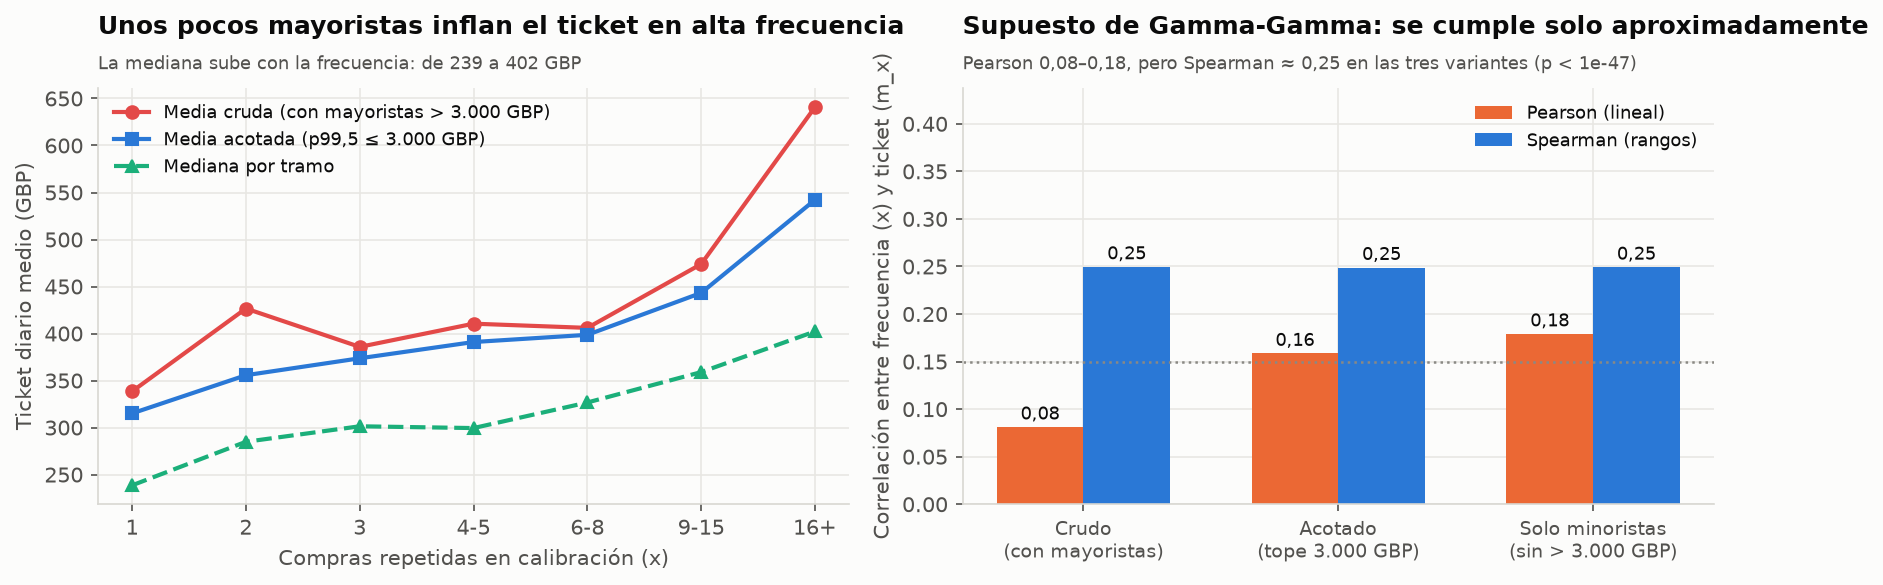

In [8]:
supuesto = evaluacion.verificar_supuesto_gamma_gamma(df_btyd)
display(supuesto)
display(Image(filename=str(config.FIGURAS / "02_independencia_frecuencia_ticket.png")))

In [9]:
rep = df_btyd[df_btyd["frecuencia"] >= 1]
por_tramo = rep.groupby(pd.cut(rep["frecuencia"], [0, 1, 2, 4, 8, 1000], labels=["1", "2", "3-4", "5-8", "9+"]), observed=True)["ticket_medio_acotado"].agg(["count", "median", "mean"])
por_tramo

,count,median,mean
frecuencia,,,
1,883,238.570,315.079
2,563,284.875,355.678
3-4,723,298.387,386.217
5-8,612,318.187,390.313
9+,555,374.821,479.794


**Lectura honesta:** la correlación lineal (Pearson) tras acotar el ticket es baja ($r = 0,159$), pero la de rangos (Spearman) es $\rho \approx 0,25$ con $p \approx 10^{-48}$ en las tres variantes: los clientes más frecuentes tienden a tener tickets algo mayores (la mediana sube con $x$). El supuesto de independencia de Gamma-Gamma **se cumple solo de forma aproximada**. Consecuencia práctica: el modelo tiende a contraer demasiado el ticket de los clientes muy frecuentes hacia la media poblacional, lo que contribuye a subestimar su ingreso futuro.